# Does excluding low-extent GFTM modes fix KBM mode selection?

Fusion_PhD-38e9.1. On the KBM Latin hypercubes most GFTM error is mode **selection**, not
identification: a mode close to GS2 is in GFTM's 4-mode spectrum but is not the fastest one.
Hypothesis: spurious fast modes with a short ballooning-angle **extent** win the argmax.

Data: the WIDTH-oracle scan (`wo_*` leaves; `docs/gyro_data_runs.md` in Fusion_PhD), GFTM at fixed
NBASIS_MAX=22 / NXGRID=28, FILTER=0.0, NMODES=4, 24 fixed widths 0.2-4.0, on SPR-045 (`KB_MODELS`)
and M1 (`KB_MODELS_MAST`). GS2 reference: the tail-averaged `pyro_cube_avg` bundles.
Extent: `pyrokinetics.diagnostics.extent.Extent` (branch `feature/extent_diagnostic`, 95% rule),
applied to each cube's `eigenfunctions`.

Sections: (a) the premise measured, (b) extent of spurious vs oracle modes, (c) the cutoff sweep,
plus three checks on the extent numbers. (d), the tearing-parity baseline, is DEFERRED to pyro#594:
FieldLine.compute_linear_tearing_parameter cannot read these GFTM cubes, and parity is not reimplemented here.

**The oracle (mode closest to GS2) consults the answer: it is a bound, never an accuracy.**

## Imports and settings

In [1]:
from pathlib import Path
import os
import warnings
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import pyrokinetics
from pyrokinetics import Pyro
from pyrokinetics.pyroscan import PyroScanGKOutput
from pyrokinetics.dataset_wrapper import DatasetWrapper
from pyrokinetics.diagnostics.extent import Extent
from pyrokinetics.diagnostics.field_line import FieldLine

ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir()
)
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
load_dotenv(ROOT / "local.env", override=True)
print("pyrokinetics", pyrokinetics.__version__)

analysis_name = "kbm_extent_filter"
data_root = Path(os.environ["GK_DATA_ROOT"]).expanduser()
run_template = "Runs"
project = "LATIN_HYPERCUBE"
cases = {"SPR-045": "SPR-045", "M1": "M1"}  # database label -> case directory
scan_information = {"GFTM": "kbm_8d/wo_{width}", "GS2": "kbm_8d"}
output_dir = {"GFTM": "pyro_cube", "GS2": "pyro_cube_avg"}  # GS2: tail-averaged reference
output_file = "cube.nc"
gs2_input_file = "gs2.in"   # per-run GS2 input (scan dir / sample name / this); pyro reads gs2.out.nc beside it
widths = ["w0p2000", "w0p2297", "w0p2639", "w0p3031", "w0p3482", "w0p4000", "w0p4595",
          "w0p5279", "w0p6063", "w0p6965", "w0p8000", "w0p9000", "w1p0000", "w1p1000",
          "w1p2000", "w1p3000", "w1p4000", "w1p5000", "w1p6000", "w1p9218", "w2p3083",
          "w2p7726", "w3p3302", "w4p0000"]
width_value = {w: float(w[1:].replace("p", ".")) for w in widths}
expected_resolution = {"nbasis_used": 22, "nxgrid_used": 28}

fraction = 0.95                             # Extent's rule: theta range holding 95% of |Re field|^2
fields = ["phi", "apar"]                    # phi selects; apar reported alongside
cutoffs = np.round(np.arange(0, 12.01, 0.25), 2)       # absolute extent cutoff [rad]
rel_cutoffs = np.round(np.arange(0, 1.001, 0.05), 2)   # fraction of the case's largest unstable-mode extent
edge_amplitude = 0.05    # check 1: |phi| at the theta-grid edge above this fraction of its peak
delta_lim = 0.2          # fig 2 colour range for the medlog change (clipped; misses-dominate cells are grey)
example_width = "w1p0000"
n_examples = 3

pyrokinetics 0.9.2.dev30+gfa3864e7


## Load data

One `PyroScanGKOutput` per (database, width), read from the cube's netCDF. The extent branch has no
`PyroHypercube` or GFTM reader, so the cube is loaded as the scan's gk_output object, which carries
units. `Extent` adds `extent(sample, field, mode)` and `bounds(..., bound=lo/hi)` in place.

In [2]:
gs2, gftm = {}, {}
for db, case in cases.items():
    gs2[db] = PyroScanGKOutput.from_netcdf(
        data_root / "GS2" / run_template / project / case / scan_information["GS2"] / output_dir["GS2"] / output_file)
    Extent(gs2[db], fraction=fraction)   # GS2 extents: used by the GFTM-vs-GS2 extent comparison at the end
    for w in widths:
        out = PyroScanGKOutput.from_netcdf(
            data_root / "GFTM" / run_template / project / case / scan_information["GFTM"].format(width=w)
            / output_dir["GFTM"] / output_file)
        Extent(out, fraction=fraction)
        gftm[db, w] = out
    print(db, "GS2 samples", gs2[db].data.sizes["sample"], "| GFTM cubes", len(widths))

SPR-045 GS2 samples 300 | GFTM cubes 24
M1 GS2 samples 300 | GFTM cubes 24


## Calculate and select

Conventions, checked rather than assumed: both codes' growth rates are in the same pyrokinetics
units; each cube's audited resolution (`*_used`, from `out.gftm.localdump`) is the requested one.

Per case, GFTM returns 4 modes. A **selector** takes the argmax growth rate over `mode` among
*unstable* modes (gamma > 0) that pass its gate. A case where no unstable mode passes is a **MISS**:
it stays in the population with gamma_sel = 0, so its |log10| error is +inf and its absolute error is
gamma_GS2. Misses therefore move the median, and medlog becomes inf once they are the majority.

Population: cases whose GS2 growth rate is finite and positive (the same cases for every selector
and width, so every comparison is paired).

- `dominant`: no gate (c = 0; the current argmax over unstable modes).
- `oracle`: the unstable mode with the smallest |log10(gamma/gamma_GS2)| -- a bound.
- `extent >= c`: absolute cutoff on the 95% extent of phi (apar alongside).
- `extent >= r * max extent`: relative cutoff on the case's own longest unstable mode.

In [3]:
def mag(v):
    return np.asarray(getattr(v.data, "magnitude", v.data))


def select(gam, keep):
    # argmax growth over 'mode' among unstable modes passing `keep`; 0 where none passes (a MISS)
    g = np.where(keep & (gam > 0), gam, -np.inf)
    idx = g.argmax(axis=1)
    return np.where(np.isfinite(g.max(axis=1)), gam[np.arange(len(gam)), idx], 0.0), idx


def score(g_sel, g_ref):
    with np.errstate(divide="ignore"):
        log_err = np.abs(np.log10(g_sel / g_ref))
    return np.median(np.abs(g_sel - g_ref)), np.median(log_err), int((g_sel == 0).sum())


rows, sweep, cases_data = [], [], {}
for (db, w), out in gftm.items():
    d, ref = out.data, gs2[db].data
    assert str(d.growth_rate.data.units) == str(ref.growth_rate.data.units), "normalisations differ"
    for var, value in expected_resolution.items():
        assert (mag(d[var]) == value).all(), f"{db}/{w}: {var} is not {value}"
    assert np.allclose(mag(d.width_used), width_value[w])

    ref_by_name = dict(zip(ref.sample_name.values, mag(ref.growth_rate)))
    g_ref_all = np.array([ref_by_name.get(n, np.nan) for n in d.sample_name.values])
    ok = np.isfinite(g_ref_all) & (g_ref_all > 0)
    g_ref = g_ref_all[ok]
    gam = mag(d.growth_rate.transpose("sample", "mode"))[ok]
    ext = {f: mag(d.extent.sel(field=f).transpose("sample", "mode"))[ok] for f in fields}
    theta = d.theta.values
    phi = mag(d.eigenfunctions.sel(field="phi").transpose("sample", "theta", "mode"))[ok]

    unstable = gam > 0
    g_dom, i_dom = select(gam, True)
    with np.errstate(divide="ignore", invalid="ignore"):
        dist = np.where(unstable, np.abs(np.log10(gam / g_ref[:, None])), np.inf)
    i_orc = dist.argmin(axis=1)
    g_orc = np.where(unstable.any(axis=1), gam[np.arange(len(gam)), i_orc], 0.0)

    # check 1: 95% bounds within one grid spacing of the edge, or |phi| at the edge above edge_amplitude of peak
    lo, hi = (mag(d.bounds.sel(field="phi", bound=b).transpose("sample", "mode"))[ok] for b in ("lo", "hi"))
    dtheta = theta[1] - theta[0]
    at_edge = (lo <= theta[0] + dtheta) | (hi >= theta[-1] - dtheta)
    edge_amp = np.maximum(np.abs(phi[:, 0]), np.abs(phi[:, -1])) / np.abs(phi).max(axis=1)

    # check 2: rotate each eigenfunction so its peak is real, recompute Extent
    e = mag(d.eigenfunctions)
    axis = d.eigenfunctions.get_axis_num("theta")
    peak = np.take_along_axis(e, np.abs(e).argmax(axis=axis, keepdims=True), axis=axis)
    rot = DatasetWrapper(data_vars={"eigenfunctions": d.eigenfunctions.copy(data=e * np.exp(-1j * np.angle(peak)))})
    Extent(rot, fraction=fraction)
    with np.errstate(divide="ignore", invalid="ignore"):
        phase_change = {f: np.abs(mag(rot.data.extent.sel(field=f).transpose("sample", "mode"))[ok] - ext[f]) / ext[f]
                        for f in fields}
    del rot

    differ = i_dom != i_orc
    with np.errstate(divide="ignore"):
        err_dom, err_orc = np.abs(np.log10(g_dom / g_ref)), np.abs(np.log10(g_orc / g_ref))
    r = np.arange(len(gam))
    row = dict(db=db, width=width_value[w], n=int(ok.sum()), n_gs2_stable_or_nan=int((~ok).sum()),
               differ=int(differ.sum()),
               medlog_dom=score(g_dom, g_ref)[1], medlog_orc=score(g_orc, g_ref)[1],
               medAE_dom=score(g_dom, g_ref)[0], medAE_orc=score(g_orc, g_ref)[0],
               medlog_dom_agree=np.median(err_dom[~differ]), medlog_dom_differ=np.median(err_dom[differ]),
               medlog_orc_differ=np.median(err_orc[differ]),
               share_err_from_differ=err_dom[differ & np.isfinite(err_dom)].sum() / err_dom[np.isfinite(err_dom)].sum(),
               unstable_modes=int(unstable.sum()), unstable_nan_extent=int((unstable & ~np.isfinite(ext["phi"])).sum()),
               frac_bounds_at_edge=at_edge[unstable].mean(), frac_edge_amp=(edge_amp[unstable] > edge_amplitude).mean(),
               **{f"phase_{f}_median_rel_change": np.nanmedian(phase_change[f][unstable]) for f in fields},
               **{f"phase_{f}_frac_over_10pct": (phase_change[f][unstable] > 0.1).mean() for f in fields})
    for f in fields:
        a, b = ext[f][r, i_dom][differ], ext[f][r, i_orc][differ]
        row[f"{f}_ext_dom_shorter"] = (a < b).mean()
        row[f"{f}_ext_ratio_median"] = np.median(a / b)
    rows.append(row)

    longest = np.nanmax(np.where(unstable, ext["phi"], np.nan), axis=1, initial=0)
    for f in fields:
        for kind, grid in (("abs", cutoffs), ("rel", rel_cutoffs)):
            for c in grid:
                threshold = c if kind == "abs" else c * longest[:, None]
                keep = (ext[f] >= threshold) | (c == 0)   # c = 0 keeps NaN-extent modes: exactly `dominant`
                medAE, medlog, miss = score(select(gam, keep)[0], g_ref)
                sweep.append(dict(db=db, width=width_value[w], field=f, kind=kind, cutoff=c,
                                  medlog=medlog, medAE=medAE, miss=miss, n=len(g_ref)))
    cases_data[db, w] = dict(names=d.sample_name.values[ok], gam=gam, g_ref=g_ref, i_dom=i_dom, i_orc=i_orc,
                             ext=ext, err_dom=err_dom, differ=differ)

summary = pd.DataFrame(rows)
sweep = pd.DataFrame(sweep)

### (c) The cutoff sweep

For each (database, width): the cutoff minimising medlog, its miss count and change vs c = 0,
next to the oracle bound. The parity baseline (d) is deferred to pyro#594.

In [7]:
best = (sweep[np.isfinite(sweep.medlog)].sort_values("medlog").groupby(["db", "field", "kind", "width"]).head(1)
        .set_index(["db", "field", "kind", "width"]).sort_index())
base = sweep[sweep.cutoff == 0].set_index(["db", "field", "kind", "width"])
best = best.assign(medlog_c0=base.medlog, medAE_c0=base.medAE)
best = best.assign(d_medlog=best.medlog - best.medlog_c0)
best = best.join(summary.set_index(["db", "width"])[["medlog_orc"]])
for f in fields:
  print(f"--- {f}, absolute cutoff ---")
  print(best.loc[(slice(None), f, "abs"), ["cutoff", "medlog", "medlog_c0", "d_medlog", "medAE", "medAE_c0",
                                             "miss", "medlog_orc"]].round(4).to_string())
print("--- phi and apar, relative cutoff ---")
print(best.loc[(slice(None), slice(None), "rel"), ["cutoff", "medlog", "medlog_c0", "d_medlog", "miss"]].round(4).to_string())
for f in fields:
    for kind in ("abs", "rel"):
        b = best.loc[(slice(None), f, kind)]
        wins = b[b.d_medlog < 0]
        print(f"{f}/{kind}: cells where some cutoff lowers medlog: "
              + ", ".join(f"{db} {len(wins.loc[db]) if db in wins.index.get_level_values(0) else 0}/{len(widths)}" for db in cases)
              + f" | largest improvement: " + ", ".join(f"{db} {b.loc[db].d_medlog.min():+.4f}" for db in cases))

--- phi, absolute cutoff ---
                           cutoff  medlog  medlog_c0  d_medlog   medAE  medAE_c0  miss  medlog_orc
db      field kind width                                                                          
M1      phi   abs  0.2000    1.50  0.1863     0.1950   -0.0087  0.0676    0.0695     2      0.0961
                   0.2297    0.50  0.1720     0.1720    0.0000  0.0551    0.0551     0      0.0828
                   0.2639    1.50  0.1585     0.1623   -0.0038  0.0453    0.0456     1      0.0735
                   0.3031    1.50  0.1245     0.1259   -0.0013  0.0416    0.0416     0      0.0575
                   0.3482    1.50  0.1407     0.1407    0.0000  0.0428    0.0428     0      0.0470
                   0.4000    1.25  0.1307     0.1307    0.0000  0.0391    0.0391     0      0.0461
                   0.4595    0.75  0.0913     0.0913    0.0000  0.0331    0.0331     0      0.0477
                   0.5279    1.50  0.0847     0.0847    0.0000  0.0317    0.0317

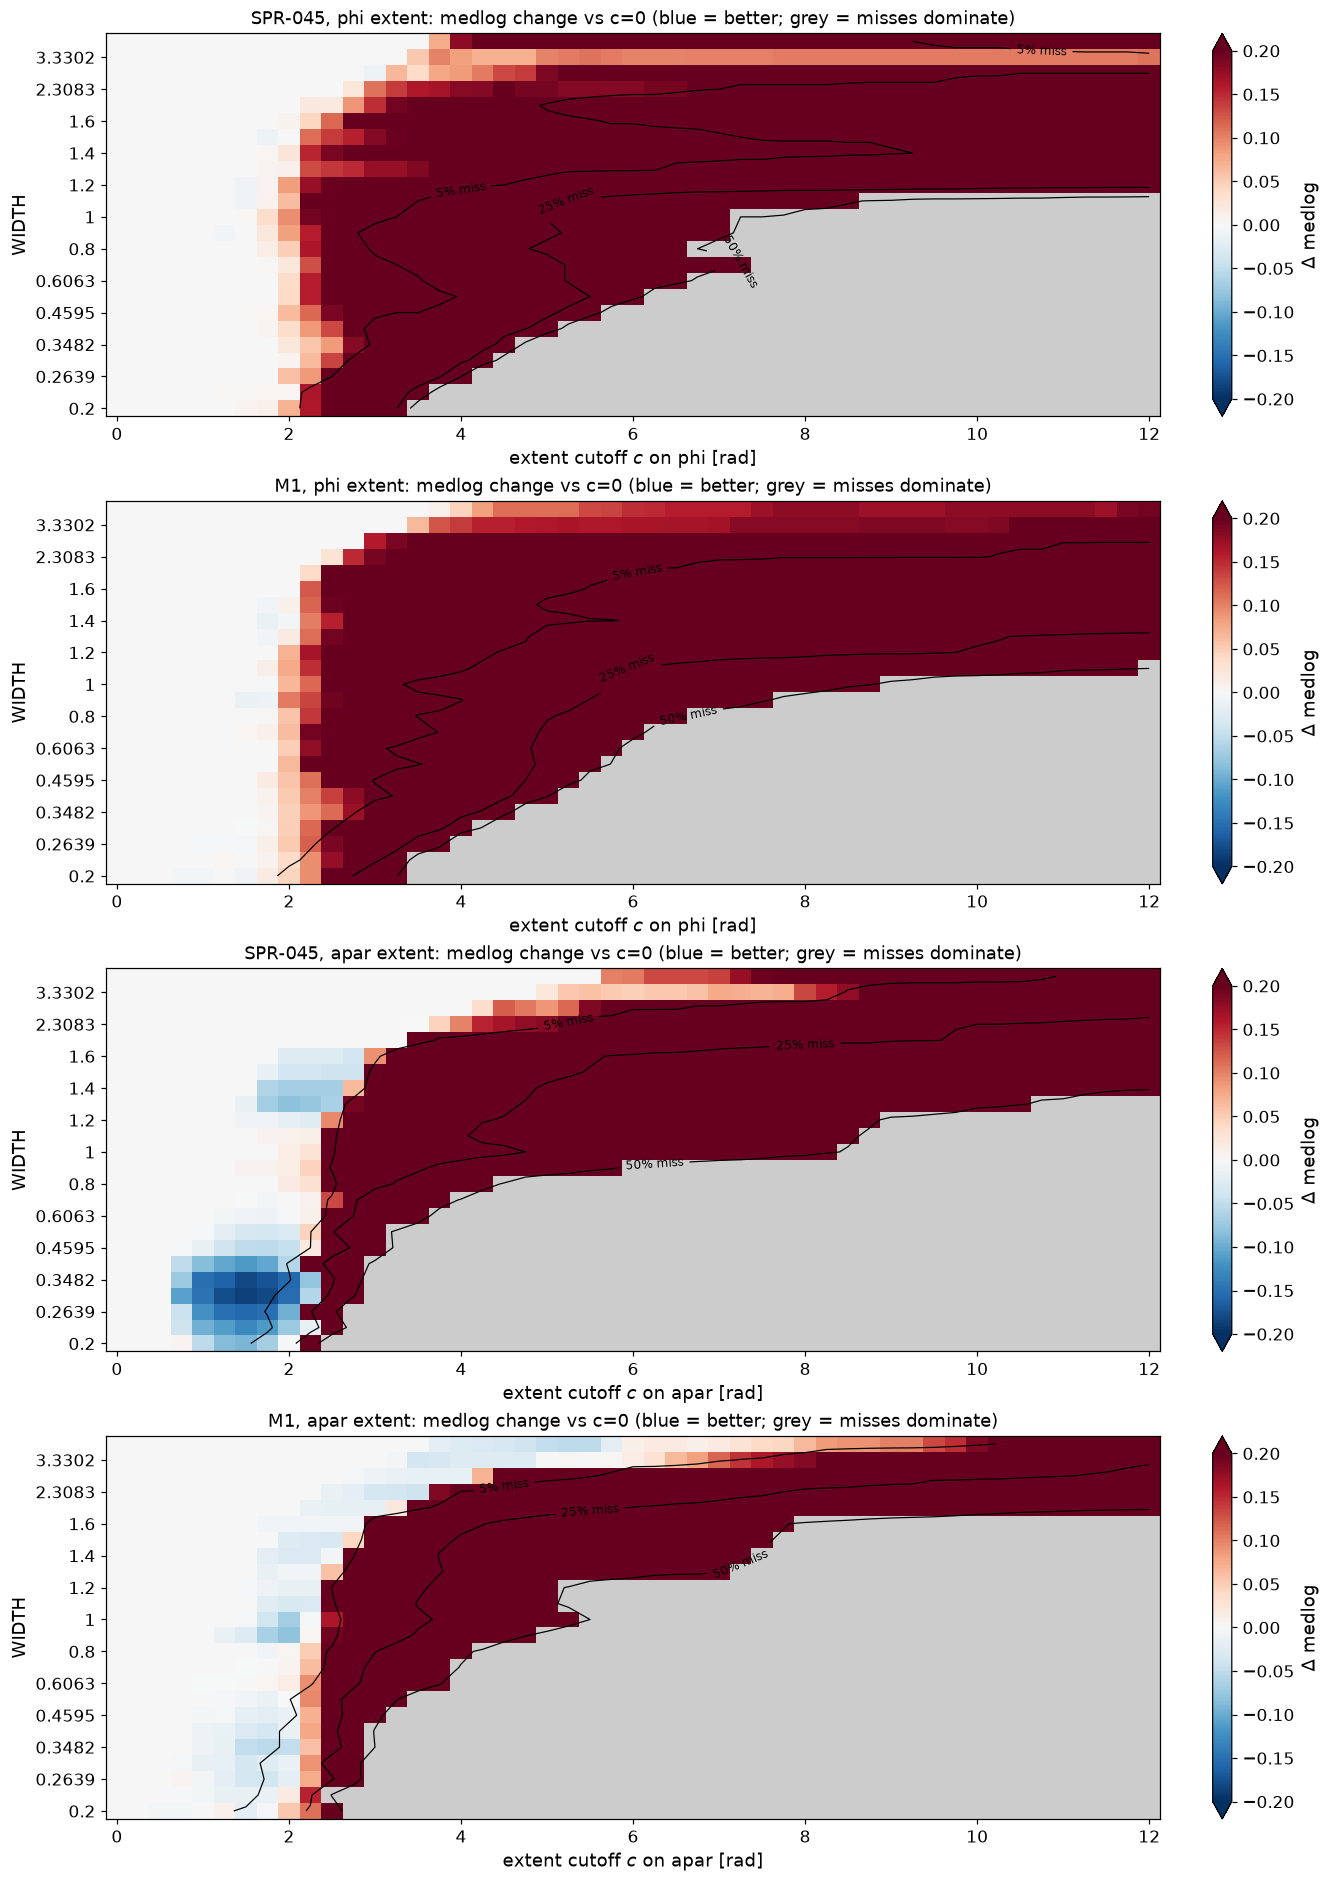

In [9]:
fig2, axes2 = plt.subplots(2 * len(fields), 1, figsize=(12, 17))
for row, (f, db) in enumerate([(f, db) for f in fields for db in cases]):
    s = sweep[(sweep.db == db) & (sweep.field == f) & (sweep.kind == "abs")]
    grid = s.pivot(index="width", columns="cutoff", values="medlog")
    delta = grid.sub(grid[0.0], axis=0)
    miss = s.pivot(index="width", columns="cutoff", values="miss") / s.n.iloc[0]
    norm = TwoSlopeNorm(0, -delta_lim, delta_lim)
    y = np.arange(len(widths))
    m = axes2[row].pcolormesh(cutoffs, y, np.ma.masked_invalid(delta.values), cmap="RdBu_r", norm=norm, shading="nearest")
    cs = axes2[row].contour(cutoffs, y, miss.values, levels=[0.05, 0.25, 0.5], colors="k", linewidths=0.8)
    axes2[row].clabel(cs, fmt=lambda v: f"{v:.0%} miss", fontsize=8)
    axes2[row].set(xlabel=f"extent cutoff $c$ on {f} [rad]", ylabel="WIDTH", yticks=y[::2],
                      yticklabels=[f"{v:g}" for v in grid.index[::2]],
                      title=f"{db}, {f} extent: medlog change vs c=0 (blue = better; grey = misses dominate)")
    axes2[row].set_facecolor("0.8")
    axes2[row].grid(False)
    fig2.colorbar(m, ax=axes2[row], label=r"$\Delta$ medlog", extend="both")
plt.show()

## Save

In [12]:
output_dir = ROOT / "Plots" / analysis_name
output_dir.mkdir(parents=True, exist_ok=True)

fig2.savefig(output_dir / "gftm_gamma_error_vs_extent_cutoff_width.png")

# How does the extent cutoff change the frequency prediction?

The cutoff sweep above scores only growth rates. Here the same selectors (FILTER=0.0 cubes; absolute and relative
cutoffs on the phi and apar extents; same GS2-unstable population) are scored on the **frequency of the selected mode**:
median |omega_GFTM - omega_GS2|. A MISS predicts omega = 0, so its error is |omega_GS2|, consistent with the FILTER=0.5
section. c = 0 is the growth-dominant mode, checked against `medAE_freq_f00`. The reference bound is the frequency
oracle (unstable mode closest to GS2 in frequency). Also reported: the frequency change at the cutoff that minimises
growth-rate medlog, i.e. what tuning the cutoff for gamma does to omega.

## Extent cutoff and frequency: calculate

In [20]:
freq_sweep = []
for (db, w), v in cases_data.items():
    d, ref = gftm[db, w].data, gs2[db].data
    assert str(d.mode_frequency.data.units) == str(ref.mode_frequency.data.units), "frequency normalisations differ"
    in_population = np.isin(d.sample_name.values, v["names"])     # same cases, same order as cases_data
    freq = mag(d.mode_frequency.transpose("sample", "mode"))[in_population]
    freq_ref_by_name = dict(zip(ref.sample_name.values, mag(ref.mode_frequency)))
    freq_ref = np.array([freq_ref_by_name[n] for n in v["names"]])
    gam, ext, r = v["gam"], v["ext"], np.arange(len(v["gam"]))
    assert np.isfinite(freq_ref).all() and np.isfinite(freq[gam > 0]).all(), f"{db}/{w}: non-finite frequency"

    longest = np.nanmax(np.where(gam > 0, ext["phi"], np.nan), axis=1, initial=0)   # as in the growth-rate sweep
    for f in fields:
        for kind, grid in (("abs", cutoffs), ("rel", rel_cutoffs)):
            for c in grid:
                threshold = c if kind == "abs" else c * longest[:, None]
                keep = (ext[f] >= threshold) | (c == 0)
                g_sel, i_sel = select(gam, keep)
                freq_sel = np.where(g_sel > 0, freq[r, i_sel], 0.0)   # a MISS predicts omega = 0
                freq_sweep.append(dict(db=db, width=width_value[w], field=f, kind=kind, cutoff=c,
                                       medAE_freq=np.median(np.abs(freq_sel - freq_ref)),
                                       miss=int((g_sel == 0).sum()), n=len(freq_ref)))
freq_sweep = pd.DataFrame(freq_sweep)


## Extent cutoff and frequency: plot

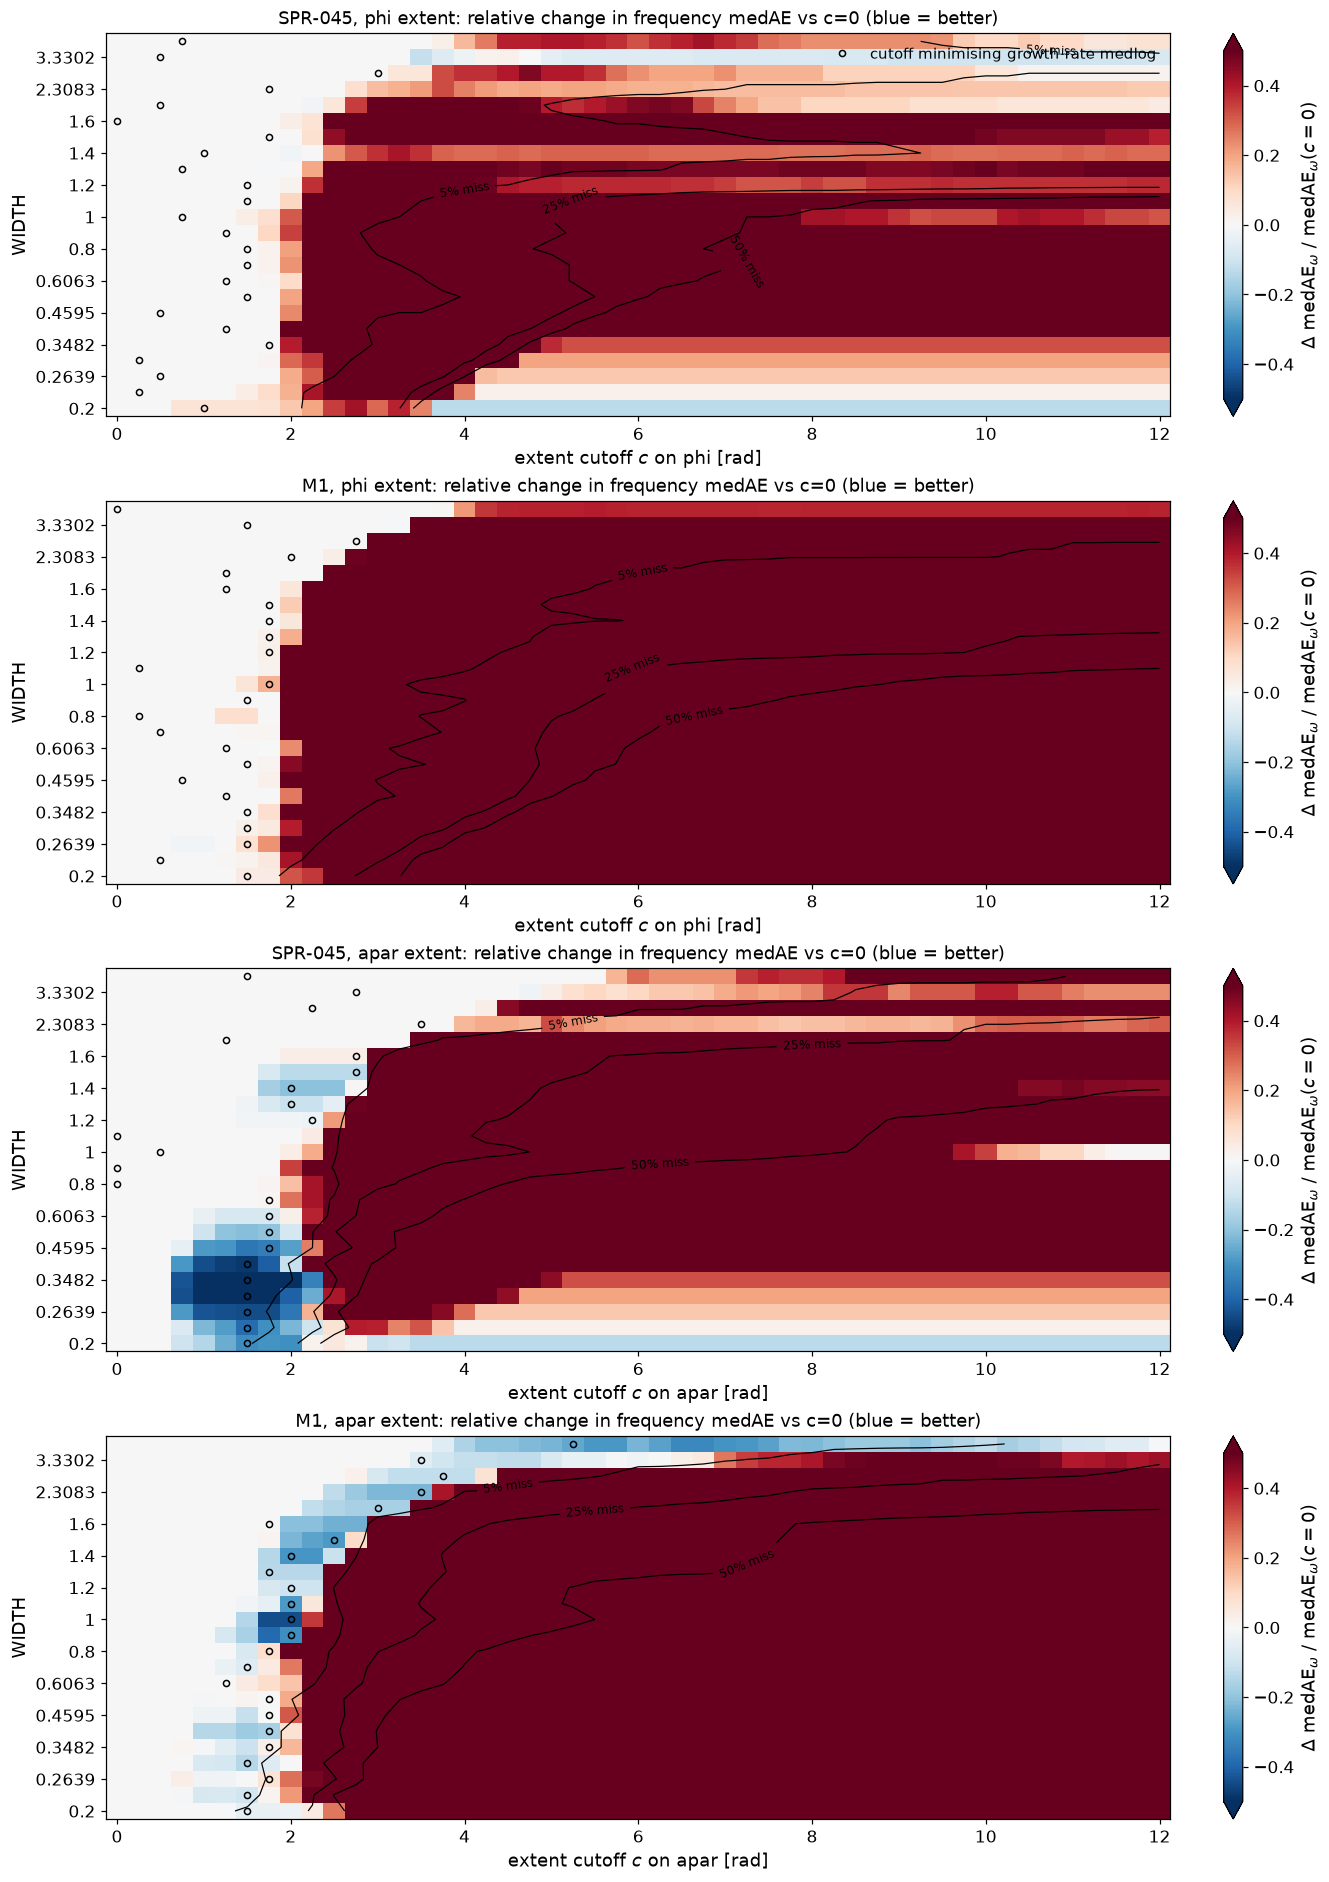

In [22]:
freq_rel_lim = 0.5   # fig 7 colour range for the relative change in frequency medAE (clipped)
fig7, axes7 = plt.subplots(2 * len(fields), 1, figsize=(12, 17))
for row, (f, db) in enumerate([(f, db) for f in fields for db in cases]):
    s = freq_sweep[(freq_sweep.db == db) & (freq_sweep.field == f) & (freq_sweep.kind == "abs")]
    grid = s.pivot(index="width", columns="cutoff", values="medAE_freq")
    rel = grid.div(grid[0.0], axis=0) - 1
    miss = s.pivot(index="width", columns="cutoff", values="miss") / s.n.iloc[0]
    y = np.arange(len(widths))
    m = axes7[row].pcolormesh(cutoffs, y, rel.values, cmap="RdBu_r", norm=TwoSlopeNorm(0, -freq_rel_lim, freq_rel_lim), shading="nearest")
    cs = axes7[row].contour(cutoffs, y, miss.values, levels=[0.05, 0.25, 0.5], colors="k", linewidths=0.8)
    axes7[row].clabel(cs, fmt=lambda v: f"{v:.0%} miss", fontsize=8)
    axes7[row].plot(best.loc[(db, f, "abs")].cutoff.values, y, "o", color="k", mfc="none", ms=4,
                    label="cutoff minimising growth-rate medlog")
    axes7[row].set(xlabel=f"extent cutoff $c$ on {f} [rad]", ylabel="WIDTH", yticks=y[::2],
                   yticklabels=[f"{v:g}" for v in grid.index[::2]],
                   title=f"{db}, {f} extent: relative change in frequency medAE vs c=0 (blue = better)")
    axes7[row].grid(False)
    fig7.colorbar(m, ax=axes7[row], label=r"$\Delta$ medAE$_\omega$ / medAE$_\omega(c=0)$", extend="both")
axes7[0].legend(loc="upper right")
plt.show()


In [23]:
fig7.savefig(ROOT / "Plots" / analysis_name / "gftm_omega_error_vs_extent_cutoff_width.png")
